# House Price Prediction using Machine Learning

## Project Overview
This project aims to predict house prices using Machine Learning regression algorithms.

The project uses housing data to identify important factors affecting house prices and builds predictive models to estimate property values.

## Objectives
- Explore and analyze housing data.
- Handle missing values.
- Perform feature engineering.
- Encode categorical variables.
- Apply feature scaling.
- Train regression models.
- Evaluate and compare model performance.
- Predict house prices using the trained model.

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Google Colab


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Display dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records: 0


In [4]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nTarget Variable:")
print("MedHouseVal")

print("\nFirst 10 Records:")
display(df.head(10))

Dataset Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Target Variable:
MedHouseVal

First 10 Records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


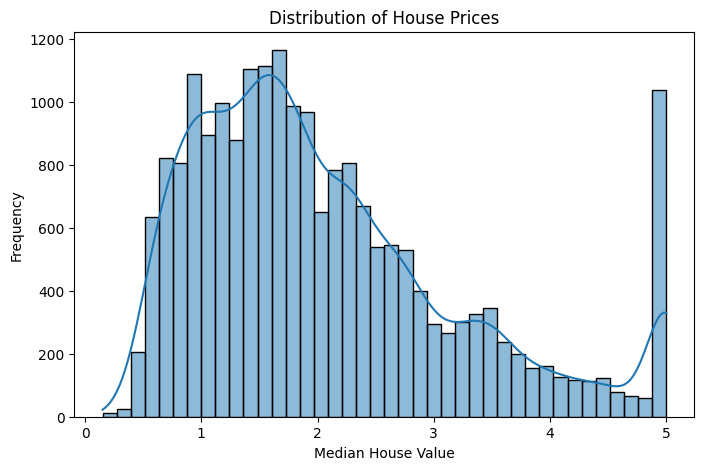

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(df['MedHouseVal'], bins=40, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

plt.savefig('house_price_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

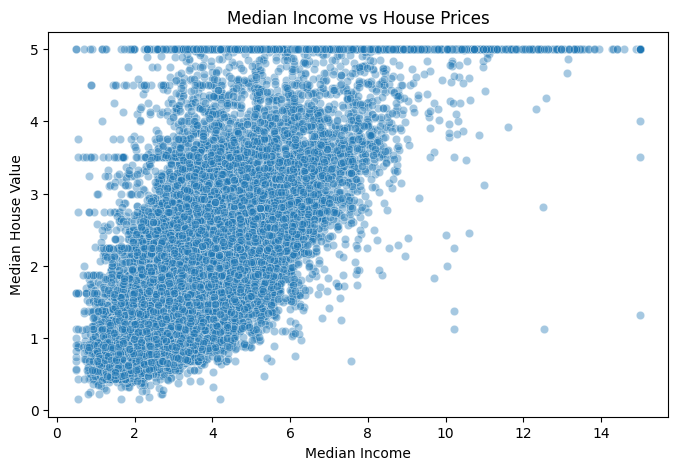

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='MedInc',
    y='MedHouseVal',
    alpha=0.4
)

plt.title('Median Income vs House Prices')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')

plt.savefig('income_vs_house_price.png', dpi=300, bbox_inches='tight')
plt.show()

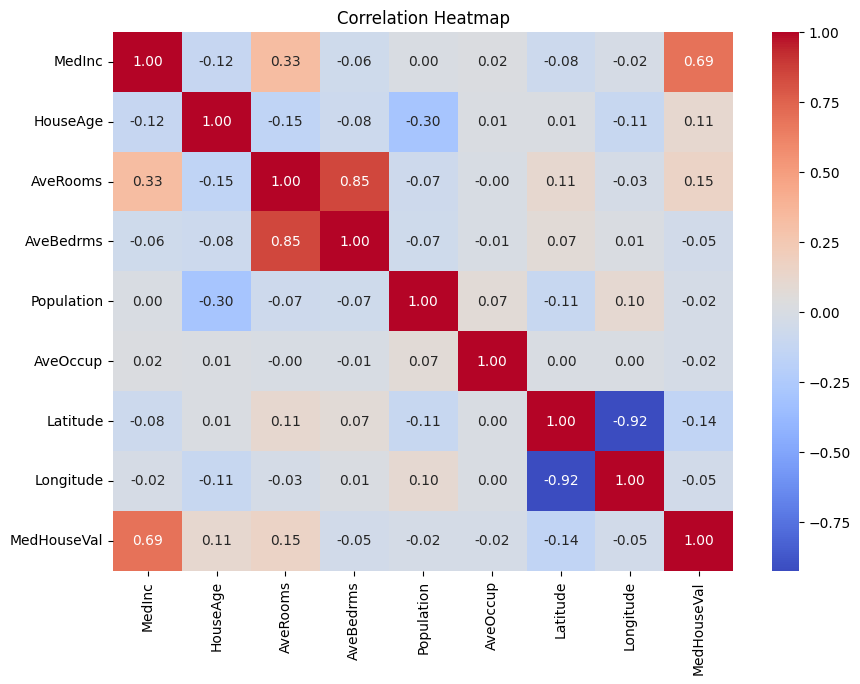

In [7]:
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Fill missing numerical values with median
for column in df.columns:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)

Missing values before cleaning:
0

Missing values after cleaning:
0
Dataset shape after cleaning: (20640, 9)


In [9]:
# Create additional features
df['RoomsPerBedroom'] = df['AveRooms'] / (df['AveBedrms'] + 0.001)

df['BedroomsPerRoom'] = df['AveBedrms'] / (df['AveRooms'] + 0.001)

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,RoomsPerBedroom,BedroomsPerRoom
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,6.815049,0.146570
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,6.412028,0.155772
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,7.713867,0.129500
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,5.416229,0.184427
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,5.805344,0.172068


In [10]:
X = df.drop('MedHouseVal', axis=1)

y = df['MedHouseVal']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (20640, 10)
Target variable shape: (20640,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16512
Testing records: 4128


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed!
Training shape: (16512, 10)
Testing shape: (4128, 10)


In [13]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [14]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
baseline_model = DummyRegressor(strategy='mean')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [16]:
def evaluate_model(name, actual, predicted):

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    return {
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }


results = pd.DataFrame([
    evaluate_model('Baseline', y_test, baseline_predictions),
    evaluate_model('Linear Regression', y_test, lr_predictions),
    evaluate_model('Random Forest', y_test, rf_predictions)
])

display(results.round(4))

,Model,RMSE,MAE,R2 Score
0,Baseline,1.1449,0.9061,-0.0002
1,Linear Regression,0.7250,0.5251,0.5989
2,Random Forest,0.5057,0.3284,0.8048


In [17]:
cv_scores = cross_val_score(
    LinearRegression(),
    X_train_scaled,
    y_train,
    cv=5,
    scoring='r2'
)

print("Cross-validation R2 scores:", cv_scores)

print("Average R2 Score:", cv_scores.mean())

Cross-validation R2 scores: [0.62406885 0.62255684 0.62070788 0.61476061 0.61327659]
Average R2 Score: 0.6190741543278004


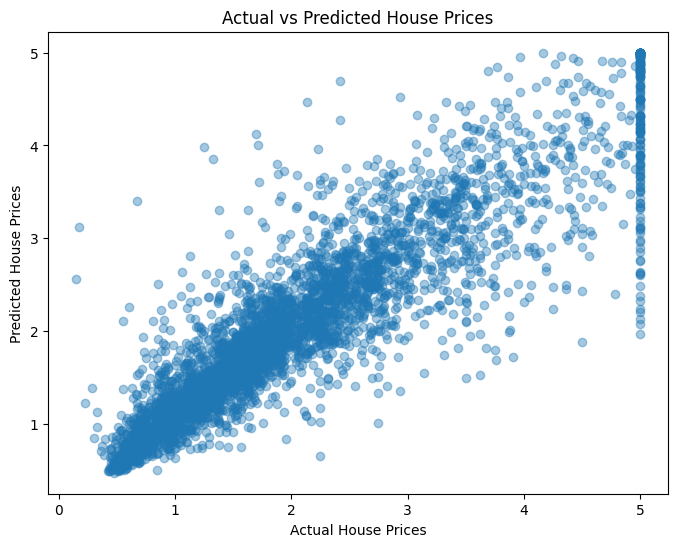

In [18]:
best_model = rf_model if results.loc[
    results['Model'] == 'Random Forest', 'R2 Score'
].iloc[0] >= results.loc[
    results['Model'] == 'Linear Regression', 'R2 Score'
].iloc[0] else lr_model

best_predictions = rf_predictions if best_model == rf_model else lr_predictions

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.4)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')

plt.title('Actual vs Predicted House Prices')

plt.savefig('actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()

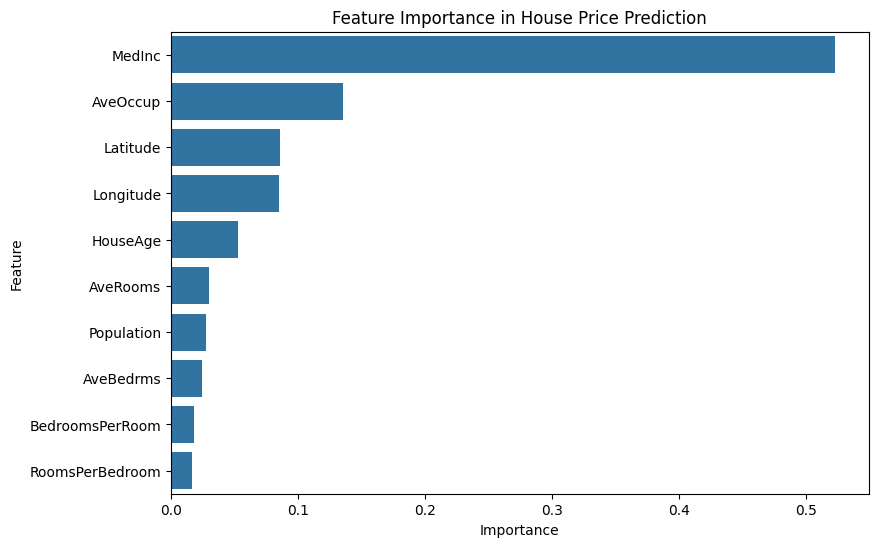

,Feature,Importance
0,MedInc,0.523328
5,AveOccup,0.135170
6,Latitude,0.085455
7,Longitude,0.085252
1,HouseAge,0.053110
2,AveRooms,0.030107
4,Population,0.027637
3,AveBedrms,0.024773
9,BedroomsPerRoom,0.018369
8,RoomsPerBedroom,0.016799


In [19]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance in House Price Prediction')

plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

display(importance)

In [20]:
# Create sample house data
new_house = pd.DataFrame([{
    'MedInc': 5.0,
    'HouseAge': 30.0,
    'AveRooms': 6.0,
    'AveBedrms': 1.2,
    'Population': 1000.0,
    'AveOccup': 3.0,
    'Latitude': 34.0,
    'Longitude': -118.0,
    'RoomsPerBedroom': 6.0 / 1.201,
    'BedroomsPerRoom': 1.2 / 6.001
}])

# Predict house value
predicted_price = best_model.predict(
    scaler.transform(new_house)
) if best_model == lr_model else best_model.predict(new_house)

print("Predicted Median House Value:", round(predicted_price[0], 4))

print("Approximate Price: $", round(predicted_price[0] * 100000, 2))

Predicted Median House Value: 2.3779
Approximate Price: $ 237788.0


In [21]:
import joblib

model_package = {
    'model': best_model,
    'scaler': scaler if best_model == lr_model else None,
    'features': X.columns.tolist(),
    'model_name': 'Random Forest' if best_model == rf_model else 'Linear Regression'
}

joblib.dump(model_package, 'house_price_prediction_model.pkl')

print("Best model saved successfully!")

Best model saved successfully!


In [22]:
loaded_package = joblib.load('house_price_prediction_model.pkl')

loaded_model = loaded_package['model']

if loaded_package['scaler'] is not None:
    test_input = loaded_package['scaler'].transform(new_house)
else:
    test_input = new_house

loaded_prediction = loaded_model.predict(test_input)

print("Saved model loaded successfully!")
print("Predicted House Value:", round(loaded_prediction[0], 4))

Saved model loaded successfully!
Predicted House Value: 2.3779


In [23]:
from google.colab import files

files.download('house_price_prediction_model.pkl')
files.download('house_price_distribution.png')
files.download('income_vs_house_price.png')
files.download('correlation_heatmap.png')
files.download('actual_vs_predicted.png')
files.download('feature_importance.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
def evaluate_model(name, actual, predicted):

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    return {
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }


results = pd.DataFrame([
    evaluate_model('Baseline', y_test, baseline_predictions),
    evaluate_model('Linear Regression', y_test, lr_predictions),
    evaluate_model('Random Forest', y_test, rf_predictions)
])

display(results.round(4))

,Model,RMSE,MAE,R2 Score
0,Baseline,1.1449,0.9061,-0.0002
1,Linear Regression,0.7250,0.5251,0.5989
2,Random Forest,0.5057,0.3284,0.8048
